# Clio-Infra — what is there

A survey of the download before anything is built from it: 86 indicators, what
each covers, how regular it is, and where the United States appears.

Reads `data/inventory.json`, written by `utils/inventory.py` from the raw
workbooks. If it is missing, run `downloads.ipynb` first. Nothing here is
stored in Postgres or served over MCP yet.

In [1]:
import sys
sys.path.append("../")
sys.path.append("../../")

import json
import numpy
import pandas
from matplotlib import pyplot, colors

from lib import config
from utils import fetch, inventory, xlsx

pyplot.style.use(config.glyfish_style)
pandas.set_option("display.max_rows", 120)
pandas.set_option("display.width", 160)

inv = json.loads((fetch.DATA_DIR / inventory.INVENTORY).read_text())
table = pandas.DataFrame([
    {"slug": slug, "category": i["category"], "indicator": i["name"],
     "countries": i["countries"], "observations": i["observations"],
     "start": i["start"], "end": i["end"], "step": i["modal_step"],
     "us_obs": i["us"]["observations"], "us_start": i["us"]["start"], "us_end": i["us"]["end"]}
    for slug, i in inv.items()]).sort_values(["category", "indicator"])
print(f"{len(table)} indicators, {table.countries.sum():,} country series, "
      f"{table.observations.sum():,} observations, {table.start.min()}–{table.end.max()}")

86 indicators, 11,044 country series, 902,291 observations, 1500–2018


## By category

A **series** here is one indicator for one country — the unit a stored series
would be. 11,044 of them, which is sixty times what meida stores today.

In [2]:
by_cat = (table.groupby("category")
          .agg(indicators=("indicator", "size"), series=("countries", "sum"),
               observations=("observations", "sum"), earliest=("start", "min"))
          .sort_values("observations", ascending=False))
by_cat

,indicators,series,observations,earliest
category,,,,
Institutions,15,2500,355014,1500
Production,12,798,184363,1681
Demography,13,2091,107489,1500
Agriculture,12,2064,80647,1500
Finance,5,560,51680,1500
Environment,5,801,28448,1500
Human Capital,5,579,25316,1500
Prices and Wages,7,587,23992,1500
National Accounts,2,178,18032,1500


## Coverage over time

Each row is an indicator, each column a decade, and the shade is how many
countries have **any** observation in that decade. One hue, darker for more —
this is magnitude, not identity. Empty is white.

Two things to read off it: where the long history actually is, and how thin it
gets before 1800.

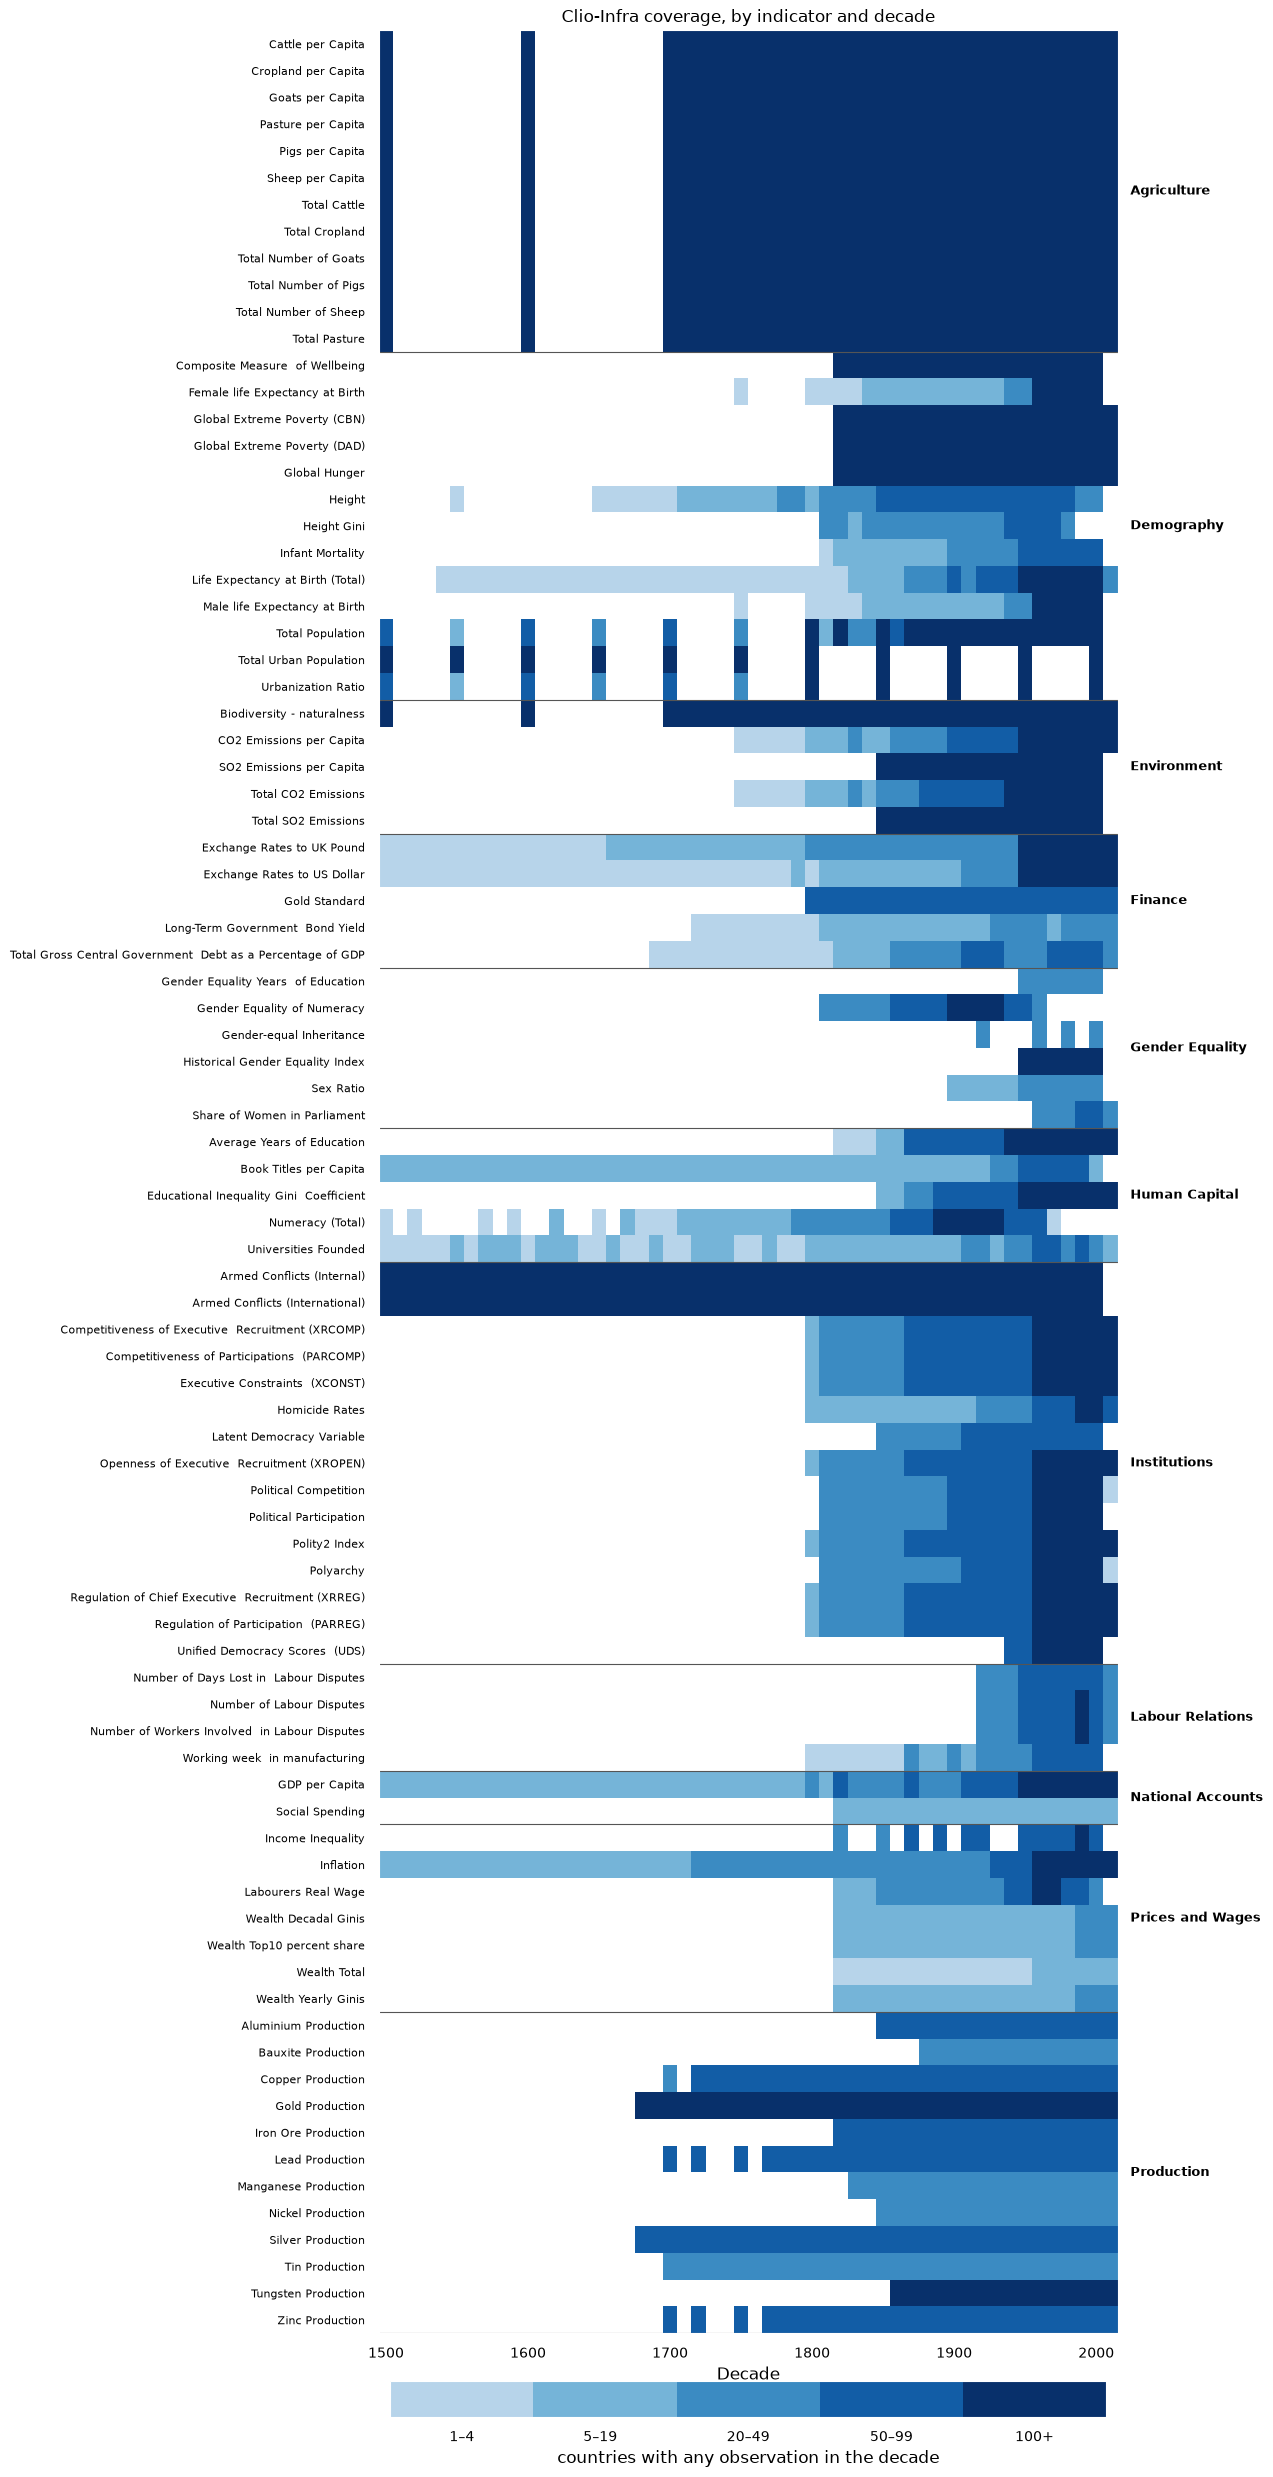

In [3]:
decades = numpy.arange(1500, 2020, 10)
rows = table.reset_index(drop=True)
grid = numpy.array([[inv[s]["countries_by_decade"].get(str(d), 0) for d in decades]
                    for s in rows.slug], dtype=float)
grid[grid == 0] = numpy.nan                                  # empty reads as white

bounds = [1, 5, 20, 50, 100, 250]
cmap = colors.ListedColormap(pyplot.get_cmap("Blues")(numpy.linspace(0.3, 1.0, len(bounds) - 1)))
cmap.set_bad("white")
norm = colors.BoundaryNorm(bounds, cmap.N)

figure, axis = pyplot.subplots(figsize=(13, 25))
image = axis.pcolormesh(decades, numpy.arange(len(rows)), grid,
                        cmap=cmap, norm=norm, shading="nearest")
axis.grid(False)
axis.set_yticks(numpy.arange(len(rows)))
axis.set_yticklabels(rows.indicator, fontsize=8)
axis.invert_yaxis()
axis.set_xlabel("Decade")

# a rule and a label at each category boundary
start = 0
for category, group in rows.groupby("category", sort=False):
    end = start + len(group)
    axis.axhline(end - 0.5, color="#555555", lw=0.8)
    axis.text(decades[-1] + 14, (start + end - 1) / 2, category, va="center",
              fontsize=9, fontweight="bold")
    start = end

bar = figure.colorbar(image, ax=axis, orientation="horizontal", pad=0.02,
                      fraction=0.015, ticks=[3, 12, 35, 75, 175])
bar.ax.set_xticklabels(["1–4", "5–19", "20–49", "50–99", "100+"])
bar.set_label("countries with any observation in the decade")
axis.set_title("Clio-Infra coverage, by indicator and decade", fontsize=12)
figure.tight_layout()

### Not every dark cell is a measurement

The chart counts countries with **any row**, and three different things produce
rows:

- **Measured series** — real wages, height, GDP, life expectancy, inequality.
  Sparse, and the coverage shown is the coverage there is.
- **Panels filled for every country.** Armed Conflicts and the Gold Standard
  are 0/1 for every country in every year — 97% of Internal Conflicts rows are
  zero. The twelve mineral-production indicators are 58–90% zeros, because most
  countries produce no tungsten. The Polity components are coded on scales of
  six to twenty-one values. Real data, but "100+ countries in 1500" means 100+
  countries coded *none*, not measured.
- **Model reconstructions at benchmark years.** The Agriculture block and
  Biodiversity are Kees Klein Goldewijk's land-use reconstructions (the HYDE
  model): every country at exactly 1500, 1600 and 1700, then every decade.
  Population and urbanisation are estimated every fifty years before 1800 —
  the stripes. Estimates spread over a grid, not observations.

So the dark band across the top of the chart before 1700 is almost entirely the
third kind. The measured long history is much thinner than it looks.

In [4]:
kinds = pandas.DataFrame([
    {"indicator": i["name"], "category": i["category"],
     "zero_share": i["zero_share"], "distinct_values": i["distinct_values"]}
    for i in inv.values() if i["zero_share"] > 0.5 or i["distinct_values"] <= 25])
print(f"{len(kinds)} indicators are mostly zeros or coded on a small scale")
kinds.sort_values("zero_share", ascending=False).set_index("indicator")

25 indicators are mostly zeros or coded on a small scale


,category,zero_share,distinct_values
indicator,,,
Armed Conflicts (Internal),Institutions,0.969,2
Armed Conflicts (International),Institutions,0.929,2
Tungsten Production,Production,0.898,528
Gold Standard,Finance,0.857,2
Gold Production,Production,0.787,3254
Aluminium Production,Production,0.778,1848
Silver Production,Production,0.769,3145
Tin Production,Production,0.739,1026
Nickel Production,Production,0.731,711


## Every indicator

`step` is the usual gap between consecutive years for one country — **1** is
annual, **10** decadal. Most annual indicators still have holes, so a line plot
of any of them needs the gaps broken rather than bridged, as Voteview's does.

In [5]:
table.drop(columns="slug").set_index(["category", "indicator"])

countries  observations  start   end  step  us_obs  us_start  us_end
category          indicator                                                                                                               
Agriculture       Cattle per Capita                                         175          7456   1500  2010    10      42    1600.0  2010.0
                  Cropland per Capita                                       184          6226   1500  2010    10      34    1500.0  2010.0
                  Goats per Capita                                          172          7037   1500  2010    10      42    1600.0  2010.0
                  Pasture per Capita                                        178          5963   1500  2010    10      33    1600.0  2010.0
                  Pigs per Capita                                           164          6841   1500  2010    10      42    1600.0  2010.0
                  Sheep per Capita                                          160          6835   1500  2010    10      42    1600.0  2010.0
                  Total Cattle                                              175          7457   1500  2010    10      42    1600.0  2010.0
                  Total Cropland                                            183          6191   1500  2010    10      34    1500.0  2010.0
                  Total Number of Goats                                     172          7037   1500  2010    10      42    1600.0  2010.0
                  Total Number of Pigs                                      164          6841   1500  2010    10      42    1600.0  2010.0
                  Total Number of Sheep                                     160          6835   1500  2010    10      42    1600.0  2010.0
                  Total Pasture                                             177          5928   1500  2010    10      33    1600.0  2010.0
Demography        Composite Measure  of Wellbeing                           193          3667   1820  2000    10      19    1820.0  2000.0
                  Female life Expectancy at Birth                           183          1058   1750  2000    10       8    1930.0  2000.0
                  Global Extreme Poverty (CBN)                              132         26268   1820  2018     1     199    1820.0  2018.0
                  Global Extreme Poverty (DAD)                              132         26268   1820  2018     1     199    1820.0  2018.0
                  Global Hunger                                             138         27462   1820  2018     1     199    1820.0  2018.0
                  Height                                                    153          1499   1550  2000    10      24    1710.0  1990.0
                  Height Gini                                               115           691   1810  1980    10      16    1810.0  1960.0
                  Infant Mortality                                          127           660   1810  2000    10       0       NaN     NaN
                  Life Expectancy at Birth (Total)                          180         12863   1543  2012     1     113    1880.0  2011.0
                  Male life Expectancy at Birth                             184          1059   1750  2000    10       8    1930.0  2000.0
                  Total Population                                          190          3221   1500  2000    10      25    1500.0  2000.0
                  Total Urban Population                                    182          1722   1500  2000    50       9    1600.0  2000.0
                  Urbanization Ratio                                        182          1051   1500  2000    50       8    1600.0  2000.0
Environment       Biodiversity - naturalness                                180          6120   1500  2010    10      34    1500.0  2010.0
                  CO2 Emissions per Capita                                  179          1724   1750  2010    10      22    1800.0  2010.0
                  SO2 Emissions per Cap

## The United States

The backlog framed Clio as extending US living standards and inequality back
centuries. Whether it does depends on the indicator — for many the long record
is Western Europe, and the US starts late.

In [6]:
us = (table[table.us_obs > 0]
      .assign(years_before_us=lambda t: t.us_start - t.start)
      .sort_values("us_start")[["category", "indicator", "us_start", "us_end", "us_obs", "start"]])
print(f"{len(us)} of {len(table)} indicators have any US data")
us.set_index("indicator")

85 of 86 indicators have any US data


,category,us_start,us_end,us_obs,start
indicator,,,,,
Exchange Rates to US Dollar,Finance,1500.0,2013.0,514,1500
Cropland per Capita,Agriculture,1500.0,2010.0,34,1500
Biodiversity - naturalness,Environment,1500.0,2010.0,34,1500
Total Population,Demography,1500.0,2000.0,25,1500
Armed Conflicts (Internal),Institutions,1500.0,2000.0,501,1500
Total Cropland,Agriculture,1500.0,2010.0,34,1500
Armed Conflicts (International),Institutions,1500.0,2000.0,501,1500
Urbanization Ratio,Demography,1600.0,2000.0,8,1500
Total Urban Population,Demography,1600.0,2000.0,9,1500


## Data quality

**Country codes.** Code and name are one-to-one wherever a code is present —
194 of each. But 861 rows carry a name and no code: Sudan, Canada and Morocco
in some files (they have codes elsewhere), and eight territories that are never
coded anywhere — Palestine, Macau, Jersey, the Isle of Man, the Cayman Islands,
the Netherlands Antilles, the US Virgin Islands and the Cook Islands. They are
kept, identified by name.

**The index counts are approximate.** Spans agree for 85 of 86. Counts agree
for 59; the rest hold *more* than the index says — three by exactly their
uncoded rows, the others by a few percent, consistent with the badges being
computed from a slightly earlier snapshot. The files are what counts.

In [7]:
quality = pandas.DataFrame([
    {"indicator": i["name"], "without_code": i["rows_without_code"],
     "file": i["observations"], "index": i["published"]["count"],
     "difference": i["count_vs_published"]}
    for i in inv.values() if i["rows_without_code"] or i["count_vs_published"]])
quality.sort_values("difference", key=abs, ascending=False).set_index("indicator")

,without_code,file,index,difference
indicator,,,,
Global Hunger,199,27462,27263,199
Global Extreme Poverty (CBN),199,26268,26069,199
Global Extreme Poverty (DAD),199,26268,26069,199
GDP per Capita,135,17742,17675,67
Labourers Real Wage,24,5084,5053,31
Working week in manufacturing,105,3998,3974,24
Infant Mortality,0,660,641,19
Wealth Top10 percent share,0,240,225,15
Wealth Decadal Ginis,0,240,225,15


## A first look — real wages

Building labourers' daily wage divided by the cost of a subsistence basket: how
many baskets a day's work bought. Read straight from the raw workbook — there
are no stored series yet. Lines break where a country's record has a gap
rather than bridging it.

Text(0.995, 0.005, 'clio-infra.eu/data/LabourersRealWage_Compact.xlsx')

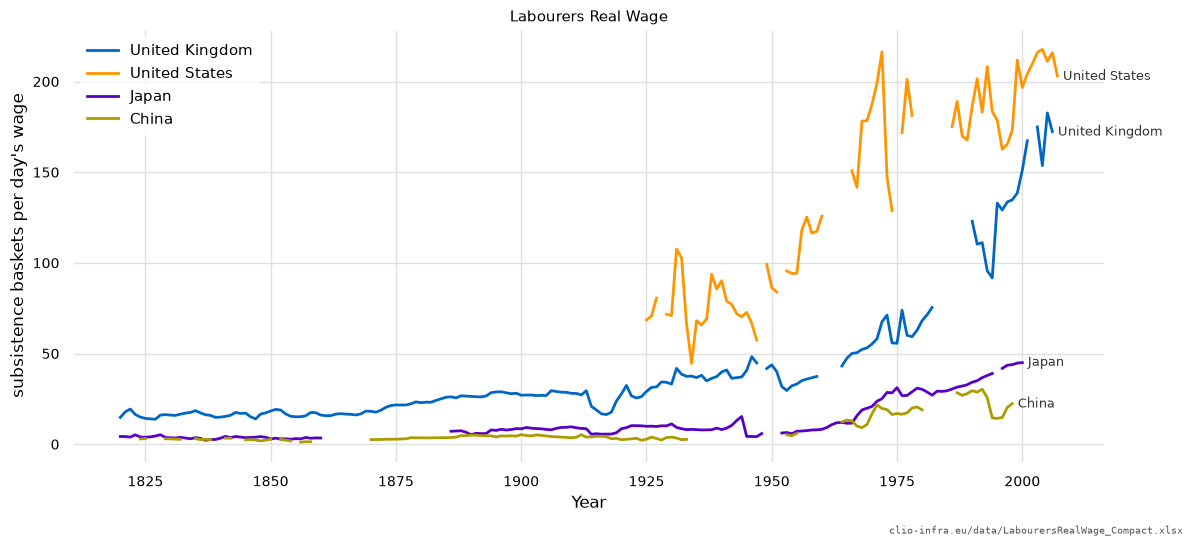

In [8]:
path = fetch.DATA_DIR / fetch.RAW / inv["LabourersRealWage"]["file"]
wage = {}
for rec in xlsx.records(path, inventory.LONG):
    wage.setdefault(rec["country.name"], []).append((int(float(rec["year"])), float(rec["value"])))

figure, axis = pyplot.subplots(figsize=(12, 5.5))
for country in ("United Kingdom", "United States", "Japan", "China"):
    points = sorted(wage[country])
    years = numpy.array([y for y, _ in points]); values = numpy.array([v for _, v in points])
    grid_years = numpy.arange(years[0], years[-1] + 1)
    lookup = dict(zip(years.tolist(), values.tolist()))
    line, = axis.plot(grid_years, [lookup.get(y, numpy.nan) for y in grid_years], lw=2, label=country)
    axis.annotate(country, (years[-1], values[-1]), xytext=(4, 0), textcoords="offset points",
                  va="center", fontsize=9, color="#333333")
axis.set_ylabel("subsistence baskets per day's wage")
axis.set_xlabel("Year")
axis.set_title(inv["LabourersRealWage"]["name"], fontsize=11)
axis.legend(loc="upper left")
figure.tight_layout()
figure.subplots_adjust(bottom=0.14)
figure.text(0.995, 0.005, f"clio-infra.eu/data/{inv['LabourersRealWage']['file']}",
            ha="right", va="bottom", fontsize=7, family="monospace", alpha=0.65)

Before 1950 the long record is Britain's, and it is steady. After that the
series is **stitched from several sources**, and the joins show: the United
Kingdom reads 92 in 1994 and 133 in 1995, a 45% rise in a single year that no
labour market produced. The indicator's own page describes its method as
"cross-analysis of various datasets" — this is what that looks like from the
inside.

So the levels are only comparable within a stretch that comes from one source.
Splicing Clio onto contemporary BLS series means finding those joins first,
which is the part the backlog called fiddly — and it starts inside Clio, not at
the boundary with BLS.